# CBE 130 Lab 6: Equilibrium, Stability, and Chaos in Nonlinear ODEs

Nonlinear rate equations can sit at an equilibrium, cycle around it, or behave chaotically. The predator-prey structure studied here also appears in autocatalytic reaction networks, and the Lorenz equations come from a simplified model of natural convection in a fluid layer heated from below. In this lab, we study how solutions behave near and far from equilibrium and how the step size affects the stability of forward Euler.

## Learning Objectives

- Implement RK4 and forward Euler loops for nonlinear coupled ODEs.
- Use `solve_ivp` as a reference solution for systems with two and three dependent variables.
- Compare trajectories that start at, near, and far from an equilibrium point.
- Interpret how a parameter change shifts the equilibrium of the Lotka-Volterra system.
- Compare forward Euler results at small and large step sizes to identify numerical instability.

## Setup

Run this cell once before working through the lab. NumPy supports the array calculations, Matplotlib creates the plots, and SciPy provides `solve_ivp`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.integrate import solve_ivp

## Part 1: Lotka-Volterra Dynamics Near and Far from Equilibrium

The Lotka-Volterra model describes a prey population $x(t)$ and a predator population $y(t)$:

$$\frac{dx}{dt} = \alpha x - \beta x y$$

$$\frac{dy}{dt} = -\delta y + \gamma x y$$

Populations are measured in thousands of animals and time is measured in years. Use $\alpha = 2$ 1/year, $\beta = 1$ 1/(thousand animals year), $\gamma = 1$ 1/(thousand animals year), and $\delta = 2$ 1/year. Setting both derivatives to zero gives the nonzero equilibrium

$$x_{\mathrm{eq}} = \frac{\delta}{\gamma} = 2, \qquad y_{\mathrm{eq}} = \frac{\alpha}{\beta} = 2$$

in thousands of animals. This equilibrium is a center: small perturbations give closed orbits instead of converging or diverging.

### Question 1.1

Use an RK4 loop with $\Delta t = 0.005$ years to simulate $0 \leq t \leq 40$ years for two initial conditions:

- Case 1 (exact equilibrium): $x(0) = 2$ thousand and $y(0) = 2$ thousand.
- Case 2 (slight deviation): $x(0) = 2(1 + \varepsilon)$ and $y(0) = 2(1 - \varepsilon)$ thousand, with $\varepsilon = 0.05$.

For the state vector $Y_n = [x_n, y_n]^T$, the RK4 update is

$$k_1 = F(t_n, Y_n)$$

$$k_2 = F\left(t_n + \frac{\Delta t}{2}, Y_n + \frac{\Delta t}{2} k_1\right)$$

$$k_3 = F\left(t_n + \frac{\Delta t}{2}, Y_n + \frac{\Delta t}{2} k_2\right)$$

$$k_4 = F\left(t_n + \Delta t, Y_n + \Delta t\, k_3\right)$$

$$Y_{n+1} = Y_n + \frac{\Delta t}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right)$$

Plot $x(t)$ and $y(t)$ for each case, and plot the phase portrait of $y$ versus $x$ for Case 2 with the equilibrium marked. Print the minimum and maximum of $x$ and $y$ in thousands for each case. Explain why Case 1 stays constant and what the small deviation does in Case 2.

Case 1: exact equilibrium:
  x ranges from 2.0000 to 2.0000 thousand
  y ranges from 2.0000 to 2.0000 thousand


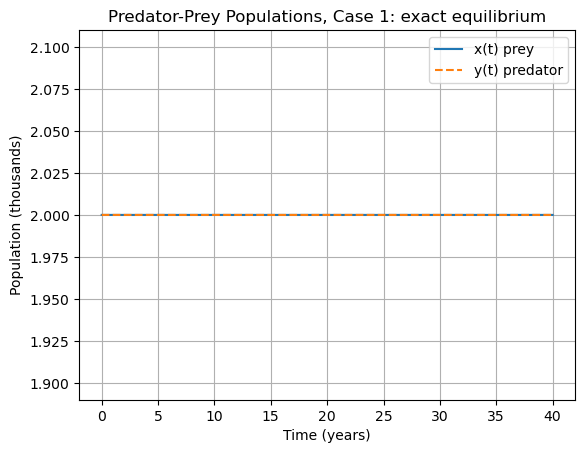

Case 2: 5% deviation:
  x ranges from 1.8618 to 2.1449 thousand
  y ranges from 1.8618 to 2.1449 thousand


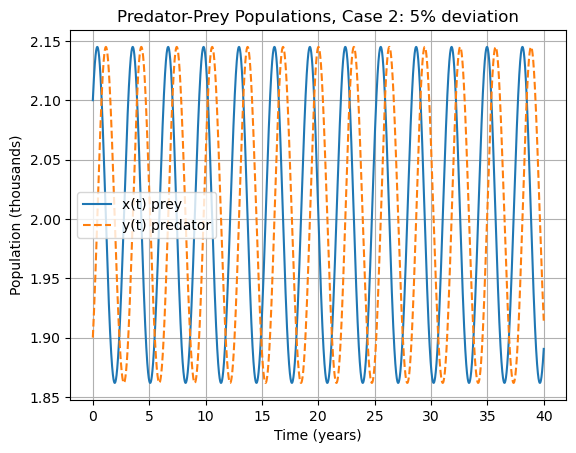

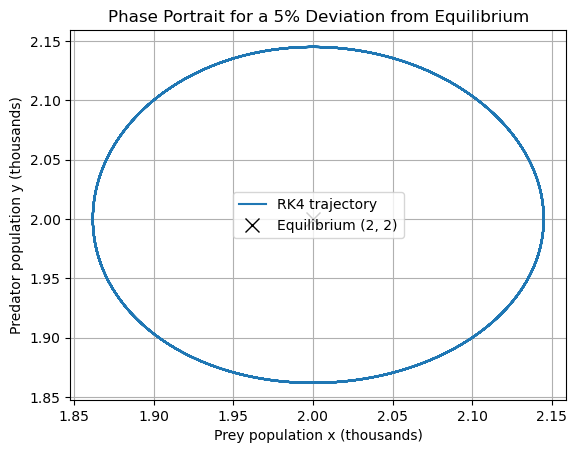

In [2]:
alpha = 2.0  # prey growth rate (1/year)
beta = 1.0   # predation rate (1/(thousand animals year))
gamma = 1.0  # predator growth from eating prey (1/(thousand animals year))
delta = 2.0  # predator death rate (1/year)

x_equilibrium = delta / gamma  # thousands
y_equilibrium = alpha / beta   # thousands

t_initial = 0.0
t_final = 40.0
t_step = 0.005
t_values = np.arange(t_initial, t_final + t_step / 2, t_step)

epsilon = 0.05
case_names = ["Case 1: exact equilibrium", "Case 2: 5% deviation"]
x_initial_values = [2.0, 2.0 * (1 + epsilon)]
y_initial_values = [2.0, 2.0 * (1 - epsilon)]

def predator_prey_rhs(t, population_values, alpha, beta, gamma, delta):
    x_current = population_values[0]  # prey population
    y_current = population_values[1]  # predator population
    dx_dt = alpha * x_current - beta * x_current * y_current
    dy_dt = -delta * y_current + gamma * x_current * y_current
    return np.array([dx_dt, dy_dt])

for case_index in range(len(case_names)):
    case_name = case_names[case_index]

    # RK4 loop: each row stores [x, y] at one time
    population_values_rk4 = np.zeros((len(t_values), 2))
    population_values_rk4[0] = [x_initial_values[case_index], y_initial_values[case_index]]

    for index in range(len(t_values) - 1):
        t_current = t_values[index]
        Y_current = population_values_rk4[index]

        k1 = predator_prey_rhs(t_current, Y_current, alpha, beta, gamma, delta)
        k2 = predator_prey_rhs(t_current + t_step / 2, Y_current + t_step * k1 / 2, alpha, beta, gamma, delta)
        k3 = predator_prey_rhs(t_current + t_step / 2, Y_current + t_step * k2 / 2, alpha, beta, gamma, delta)
        k4 = predator_prey_rhs(t_current + t_step, Y_current + t_step * k3, alpha, beta, gamma, delta)
        population_values_rk4[index + 1] = Y_current + (t_step / 6) * (k1 + 2 * k2 + 2 * k3 + k4)

    x_rk4_values = population_values_rk4[:, 0]
    y_rk4_values = population_values_rk4[:, 1]

    print(f"{case_name}:")
    print(f"  x ranges from {np.min(x_rk4_values):.4f} to {np.max(x_rk4_values):.4f} thousand")
    print(f"  y ranges from {np.min(y_rk4_values):.4f} to {np.max(y_rk4_values):.4f} thousand")

    plt.figure()
    plt.plot(t_values, x_rk4_values, label="x(t) prey")
    plt.plot(t_values, y_rk4_values, "--", label="y(t) predator")
    plt.title(f"Predator-Prey Populations, {case_name}")
    plt.xlabel("Time (years)")
    plt.ylabel("Population (thousands)")
    plt.legend()
    plt.grid(True)
    plt.show()

    if case_index == 1:
        plt.figure()
        plt.plot(x_rk4_values, y_rk4_values, label="RK4 trajectory")
        plt.plot(x_equilibrium, y_equilibrium, "kx", markersize=10, label="Equilibrium (2, 2)")
        plt.title("Phase Portrait for a 5% Deviation from Equilibrium")
        plt.xlabel("Prey population x (thousands)")
        plt.ylabel("Predator population y (thousands)")
        plt.legend()
        plt.grid(True)
        plt.show()

At the equilibrium both derivatives are zero, so every RK4 slope is zero and the populations stay at 2 thousand. A 5% deviation gives a small closed orbit around $(2, 2)$: the populations oscillate with a constant amplitude instead of returning to or moving away from the equilibrium.

### Question 1.2

Now start far from equilibrium at $x(0) = 25$ thousand and $y(0) = 0.2$ thousand, and simulate $0 \leq t \leq 60$ years. At $t_s = 30$ years, the predator death rate increases from $\delta = 2$ to $\delta = 3$, which moves the equilibrium from $(2, 2)$ to $(3, 2)$ thousand. All other parameters are the same as in Question 1.1.

Use forward Euler with $\Delta t = 0.01$ years and $\Delta t = 0.25$ years, and `solve_ivp` with $\Delta t = 0.01$ years:

$$x_{n+1} = x_n + \Delta t \left(\alpha x_n - \beta x_n y_n\right)$$

$$y_{n+1} = y_n + \Delta t \left(-\delta y_n + \gamma x_n y_n\right)$$

Stop the Euler loop if a population becomes negative, and print the time at which this happens. Overlay each Euler phase portrait on the `solve_ivp` result. Explain how each Euler result compares with `solve_ivp`.

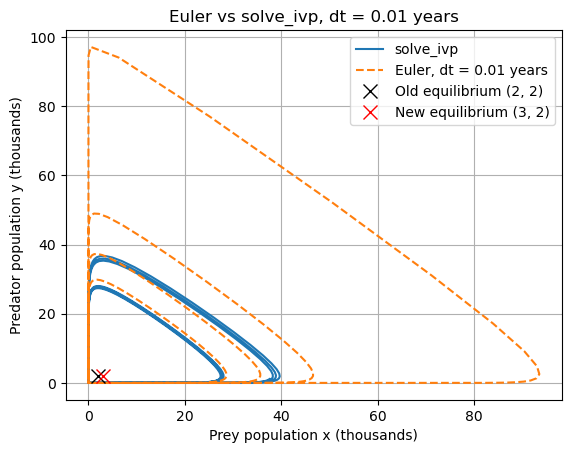

Euler with dt = 0.25 years gave a negative population at t = 0.75 years


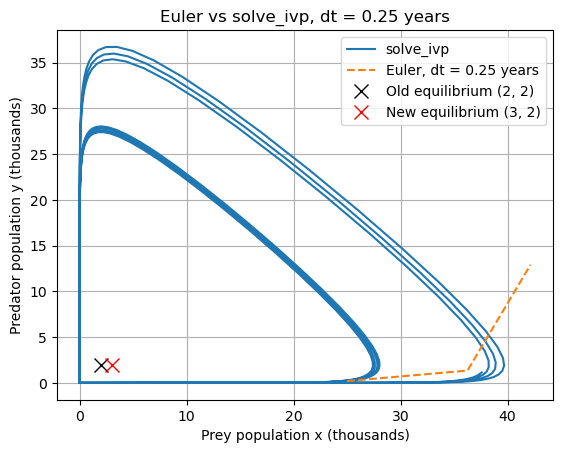

In [3]:
alpha = 2.0         # 1/year
beta = 1.0          # 1/(thousand animals year)
gamma = 1.0         # 1/(thousand animals year)
delta_before = 2.0  # 1/year
delta_after = 3.0   # 1/year
t_switch = 30.0     # years

x_equilibrium_old = delta_before / gamma  # 2 thousand
x_equilibrium_new = delta_after / gamma   # 3 thousand
y_equilibrium = alpha / beta              # 2 thousand

x_initial = 25.0  # thousands
y_initial = 0.2   # thousands
t_initial = 0.0
t_final = 60.0
t_step = 0.01
t_values = np.arange(t_initial, t_final + t_step / 2, t_step)

def F(t, population_values, alpha, beta, gamma, delta_before, delta_after, t_switch):
    # The predator death rate changes at t_switch
    if t < t_switch:
        delta = delta_before
    else:
        delta = delta_after

    x_current = population_values[0]
    y_current = population_values[1]
    dx_dt = alpha * x_current - beta * x_current * y_current
    dy_dt = -delta * y_current + gamma * x_current * y_current
    return np.array([dx_dt, dy_dt])

solution = solve_ivp(
    F,
    (t_initial, t_final),
    [x_initial, y_initial],
    t_eval=t_values,
    args=(alpha, beta, gamma, delta_before, delta_after, t_switch)
)
solution_values = solution.y.T
x_ivp_values = solution_values[:, 0]
y_ivp_values = solution_values[:, 1]

euler_t_steps = [0.01, 0.25]  # years

for euler_t_step in euler_t_steps:
    t_euler_values = np.arange(t_initial, t_final + euler_t_step / 2, euler_t_step)

    # Fill with NaN so unused entries are not plotted if the loop stops early
    Y_values = np.full((len(t_euler_values), 2), np.nan)
    Y_values[0] = np.array([x_initial, y_initial])

    for index in range(len(t_euler_values) - 1):
        x_current = Y_values[index][0]
        y_current = Y_values[index][1]
        slope_values = F(t_euler_values[index], [x_current, y_current],
                                                alpha, beta, gamma, delta_before, delta_after, t_switch)
        x_next = x_current + euler_t_step * slope_values[0]
        y_next = y_current + euler_t_step * slope_values[1]

        # Negative populations are not physical, so the method has failed
        if x_next < 0 or y_next < 0:
            print(f"Euler with dt = {euler_t_step} years gave a negative population at t = {t_euler_values[index + 1]:.2f} years")
            break

        Y_values[index+1] = np.array([x_next, y_next])

    plt.figure()
    plt.plot(x_ivp_values, y_ivp_values, label="solve_ivp")
    plt.plot(Y_values[:, 0], Y_values[:, 1], "--", label=f"Euler, dt = {euler_t_step} years")
    plt.plot(x_equilibrium_old, y_equilibrium, "kx", markersize=10, label="Old equilibrium (2, 2)")
    plt.plot(x_equilibrium_new, y_equilibrium, "rx", markersize=10, label="New equilibrium (3, 2)")
    plt.title(f"Euler vs solve_ivp, dt = {euler_t_step} years")
    plt.xlabel("Prey population x (thousands)")
    plt.ylabel("Predator population y (thousands)")
    plt.legend()
    plt.grid(True)
    plt.show()

Starting far from equilibrium gives large, sharp population spikes, but `solve_ivp` still follows closed orbits. After $\delta$ increases to 3 1/year, the orbit shifts to circle the new equilibrium $(3, 2)$. Euler with $\Delta t = 0.01$ years has the right shape but spirals outward each cycle, overpredicting the peaks. Euler with $\Delta t = 0.25$ years is unstable and gives a negative population after only 3 steps.

## Part 2: Chaotic Lorenz System

Lorenz derived the following equations as a simplified model of natural convection in a fluid layer heated from below. Here $x$ is proportional to the strength of the convective circulation, $y$ to the temperature difference between rising and falling fluid, and $z$ to the distortion of the vertical temperature profile. All variables and time are dimensionless.

$$\frac{dx}{dt} = \sigma (y - x)$$

$$\frac{dy}{dt} = x (\rho - z) - y$$

$$\frac{dz}{dt} = x y - \beta z$$

Use $\sigma = 10$, $\rho = 28$, $\beta = 8/3$, and the initial condition $(x(0), y(0), z(0)) = (-8, 8, 27)$. For these values the solution is chaotic: it never settles to an equilibrium or a repeating cycle, and small differences between trajectories grow quickly.

### Question 2.1

Write the right-hand side function for the Lorenz system. Use `solve_ivp` with `t_eval` on a fixed grid with $\Delta t = 0.01$ for $0 \leq t \leq 30$. Plot $x(t)$, $y(t)$, and $z(t)$ on one figure, and plot the phase portrait of $z$ versus $x$.

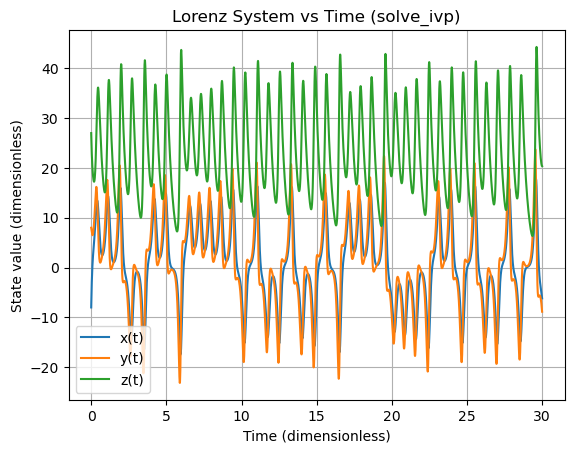

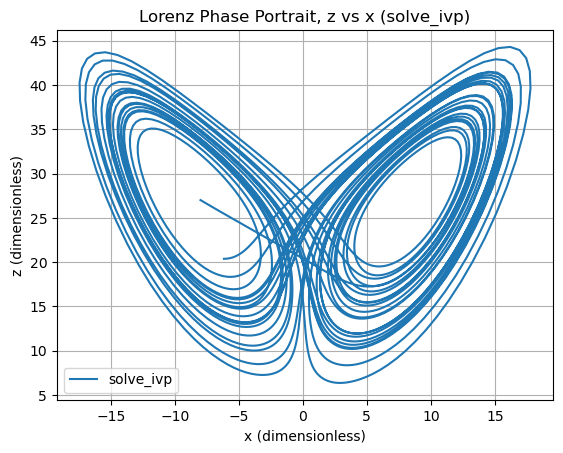

In [4]:
sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0
IC = np.array([-8.0, 8.0, 27.0])  # [x, y, z] at t = 0

t_initial = 0.0
t_final = 30.0
t_step = 0.01
t_values = np.arange(t_initial, t_final + t_step / 2, t_step)

def lorenz_rhs(t, state_values, sigma, rho, beta):
    x_current = state_values[0]
    y_current = state_values[1]
    z_current = state_values[2]
    dx_dt = sigma * (y_current - x_current)
    dy_dt = x_current * (rho - z_current) - y_current
    dz_dt = x_current * y_current - beta * z_current
    return np.array([dx_dt, dy_dt, dz_dt])

solution = solve_ivp(
    lorenz_rhs,
    (t_initial, t_final),
    IC,
    t_eval=t_values,
    args=(sigma, rho, beta)
)
solution_values = solution.y.T
x_ivp_values = solution_values[:, 0]
y_ivp_values = solution_values[:, 1]
z_ivp_values = solution_values[:, 2]

plt.figure()
plt.plot(t_values, x_ivp_values, label="x(t)")
plt.plot(t_values, y_ivp_values, label="y(t)")
plt.plot(t_values, z_ivp_values, label="z(t)")
plt.title("Lorenz System vs Time (solve_ivp)")
plt.xlabel("Time (dimensionless)")
plt.ylabel("State value (dimensionless)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(x_ivp_values, z_ivp_values, label="solve_ivp")
plt.title("Lorenz Phase Portrait, z vs x (solve_ivp)")
plt.xlabel("x (dimensionless)")
plt.ylabel("z (dimensionless)")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
# Interactive 3D view of the Lorenz attractor: click and drag to rotate, scroll to zoom
figure_3d = go.Figure()
figure_3d.add_trace(
    go.Scatter3d(
        x=x_ivp_values,
        y=y_ivp_values,
        z=z_ivp_values,
        mode="lines",
        line=dict(color=t_values, colorscale="Viridis", width=3, colorbar=dict(title="Time")),
        name="solve_ivp"
    )
)
figure_3d.update_layout(
    title="Lorenz Attractor in 3D (solve_ivp)",
    scene=dict(
        xaxis_title="x (dimensionless)",
        yaxis_title="y (dimensionless)",
        zaxis_title="z (dimensionless)"
    )
)
figure_3d.show()

### Question 2.2

Write a forward Euler loop for the Lorenz system:

$$x_{n+1} = x_n + \Delta t\, \sigma (y_n - x_n)$$

$$y_{n+1} = y_n + \Delta t \left[x_n (\rho - z_n) - y_n\right]$$

$$z_{n+1} = z_n + \Delta t \left(x_n y_n - \beta z_n\right)$$

Integrate for $0 \leq t \leq 30$ with a small step $\Delta t = 0.001$. Overlay the Euler phase portraits of $y$ versus $x$ and $z$ versus $x$ on the `solve_ivp` result from Question 2.1.

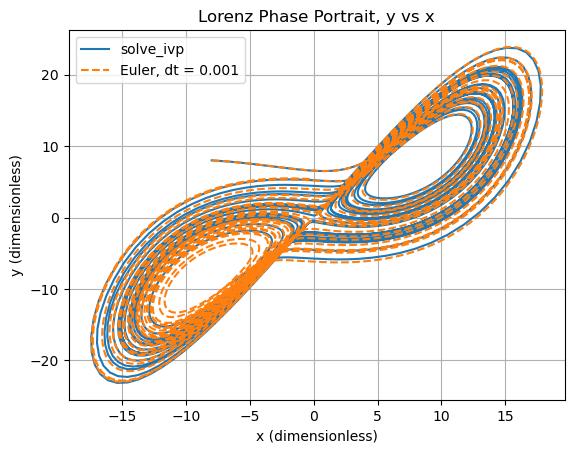

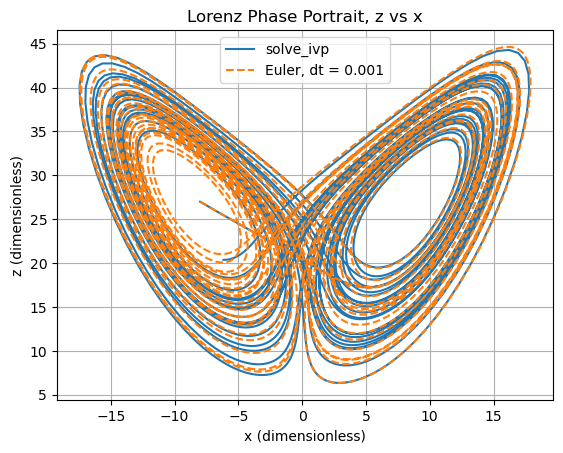

In [6]:
sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0
IC = np.array([-8.0, 8.0, 27.0])

# solve_ivp reference on a dt = 0.01 grid
t_initial = 0.0
t_final = 30.0
t_values = np.arange(t_initial, t_final + 0.01 / 2, 0.01)
solution = solve_ivp(
    lorenz_rhs,
    (t_initial, t_final),
    IC,
    t_eval=t_values,
    args=(sigma, rho, beta)
)
solution_values = solution.y.T

# Forward Euler with a small step
t_step = 0.001
t_euler_values = np.arange(t_initial, t_final + t_step / 2, t_step)
state_values_euler = np.zeros((len(t_euler_values), 3))
state_values_euler[0] = IC

for index in range(len(t_euler_values) - 1):
    state_current = state_values_euler[index]
    slope_values = lorenz_rhs(t_euler_values[index], state_current, sigma, rho, beta)
    state_values_euler[index + 1] = state_current + t_step * slope_values

plt.figure()
plt.plot(solution_values[:, 0], solution_values[:, 1], label="solve_ivp")
plt.plot(state_values_euler[:, 0], state_values_euler[:, 1], "--", label="Euler, dt = 0.001")
plt.title("Lorenz Phase Portrait, y vs x")
plt.xlabel("x (dimensionless)")
plt.ylabel("y (dimensionless)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(solution_values[:, 0], solution_values[:, 2], label="solve_ivp")
plt.plot(state_values_euler[:, 0], state_values_euler[:, 2], "--", label="Euler, dt = 0.001")
plt.title("Lorenz Phase Portrait, z vs x")
plt.xlabel("x (dimensionless)")
plt.ylabel("z (dimensionless)")
plt.legend()
plt.grid(True)
plt.show()

With $\Delta t = 0.001$, Euler traces the same butterfly-shaped attractor as `solve_ivp`. The individual trajectories separate after a few time units, because in a chaotic system small numerical errors grow quickly.

### Question 2.3

Repeat the Euler calculation with a larger step $\Delta t = 0.04$. Stop the loop if any state variable exceeds 1000 in magnitude, and print the time at which this happens. Plot the Euler phase portrait of $z$ versus $x$ with the `solve_ivp` result, and briefly explain why forward Euler fails here while `solve_ivp` does not.

Euler with dt = 0.04 blew up at t = 3.04


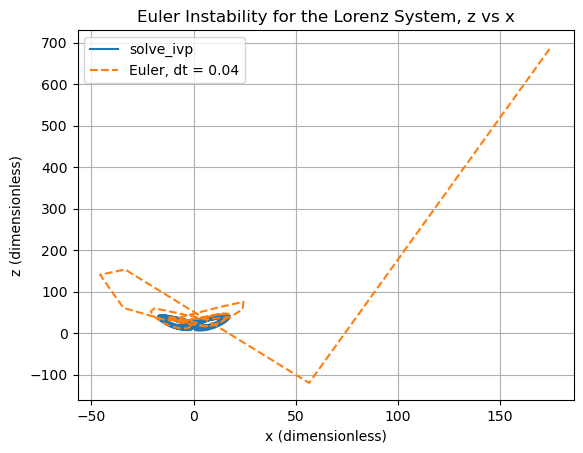

In [7]:
sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0
IC = np.array([-8.0, 8.0, 27.0])

# solve_ivp reference on a dt = 0.01 grid
t_initial = 0.0
t_final = 30.0
t_values = np.arange(t_initial, t_final + 0.01 / 2, 0.01)
solution = solve_ivp(
    lorenz_rhs,
    (t_initial, t_final),
    IC,
    t_eval=t_values,
    args=(sigma, rho, beta)
)
solution_values = solution.y.T

# Forward Euler with a large step
t_step = 0.04
t_euler_values = np.arange(t_initial, t_final + t_step / 2, t_step)

# Fill with NaN so unused entries are not plotted if the loop stops early
state_values_euler = np.full((len(t_euler_values), 3), np.nan)
state_values_euler[0] = IC

for index in range(len(t_euler_values) - 1):
    state_current = state_values_euler[index]
    slope_values = lorenz_rhs(t_euler_values[index], state_current, sigma, rho, beta)
    state_next = state_current + t_step * slope_values

    if np.max(np.abs(state_next)) > 1000:
        print(f"Euler with dt = {t_step} blew up at t = {t_euler_values[index + 1]:.2f}")
        break

    state_values_euler[index + 1] = state_next

plt.figure()
plt.plot(solution_values[:, 0], solution_values[:, 2], label="solve_ivp")
plt.plot(state_values_euler[:, 0], state_values_euler[:, 2], "--", label=f"Euler, dt = {t_step}")
plt.title("Euler Instability for the Lorenz System, z vs x")
plt.xlabel("x (dimensionless)")
plt.ylabel("z (dimensionless)")
plt.legend()
plt.grid(True)
plt.show()

With $\Delta t = 0.04$, Euler blows up at about $t = 3$. Forward Euler has a small stability region, so a large step lets the error grow each step until the solution diverges. `solve_ivp` adjusts its step size to keep the error small, so it stays on the attractor.